Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

<Figure size 1200x500 with 0 Axes>

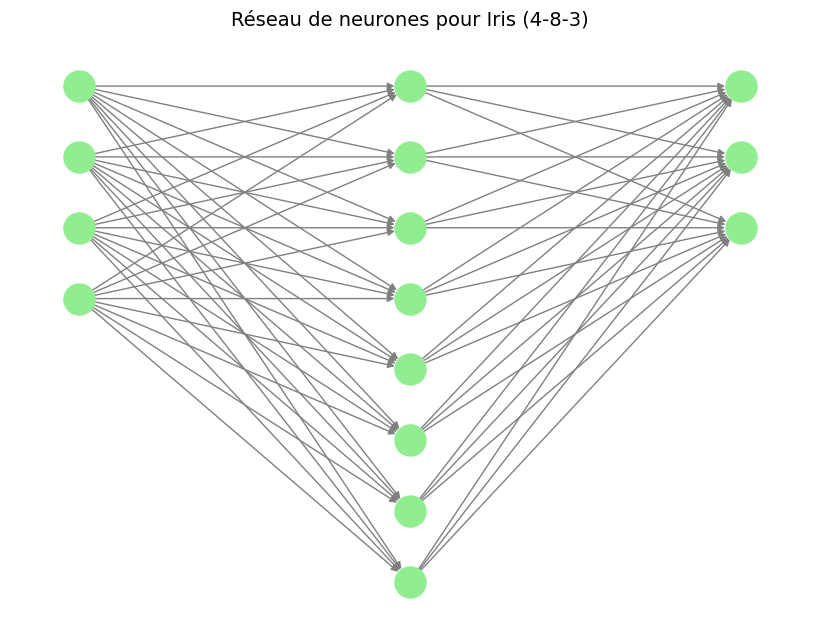

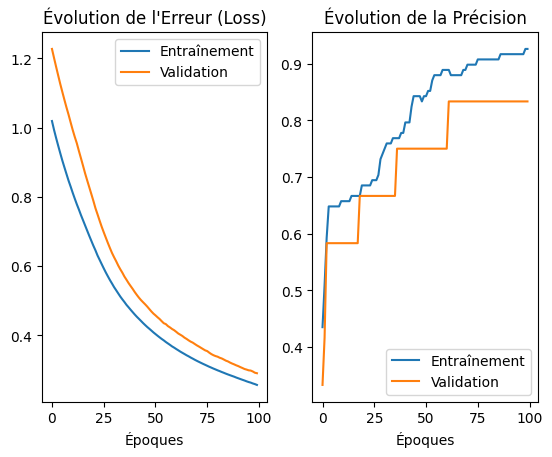


Précision (Accuracy) sur le jeu de test : 90.00%
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True_Class,Predicted_Class
0,4.4,3.0,1.3,0.2,0,0
1,6.1,3.0,4.9,1.8,2,2
2,4.9,2.4,3.3,1.0,1,1
3,5.0,2.3,3.3,1.0,1,1
4,4.4,3.2,1.3,0.2,0,0
5,6.3,3.3,4.7,1.6,1,2
6,4.6,3.6,1.0,0.2,0,0
7,5.4,3.4,1.7,0.2,0,0
8,6.5,3.0,5.2,2.0,2,2
9,5.4,3.0,4.5,1.5,1,1


In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
plt.figure(figsize=(12, 5))

# Chargement du dataset
iris = load_iris()
# Nos 4 features
X = iris.data
# Nos classes cibles (0, 1, 2)
y = iris.target

# Séparation Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, # On garde 20% des données pour tester notre modèle à la fin
    stratify=y,
    random_state=42
)

# Normalisation des données
scaler = StandardScaler()
# On ajuste (fit) ET on transforme les données d'entraînement
X_train = scaler.fit_transform(X_train)
# On se contente de transformer les données de test avec la règle apprise sur le train
X_test = scaler.transform(X_test)

# Construction de l'architecture du Modèle (MLP)
model = Sequential([
# 4 features en entrée
Input(shape=(4,)),
# Couche cachée de 8 neurones
Dense(8, activation='relu'),
# Couche de sortie de 3 neurones (pour les 3 classes)
Dense(3, activation='softmax')
])

# Compilation du Modèle
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Affichage du résumé de notre modèle
model.summary()

# dessin de l'architecture du réseau (4-8-3)
layers = [4, 8, 3]
G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    for i in range(n_neurons):
        node_id = f"L{l}N{i}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -i) # Positionner les neurones en colonnes
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

for l in range(len(layers)-1):
    for src in layer_positions[l]:
        for dst in layer_positions[l+1]:
            G.add_edge(src, dst)

plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=False,
        node_size=500, node_color="lightgreen", edge_color="gray")
plt.title("Réseau de neurones pour Iris (4-8-3)", fontsize=14)
plt.show()

# Entraînement du modèle
# L'entraînement est sauvegardé dans la variable 'history' pour pouvoir tracer des graphiques plus tard
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    # Keras va mettre de côté 10% des données d'entraînement pour calculer un score de validation
    validation_split=0.1,
    verbose=0
)

# 1. Courbe de l'erreur (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Entraînement')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Évolution de l\'Erreur (Loss)')
plt.xlabel('Époques')
plt.legend()

# 2. Courbe de la précision (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Entraînement')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Évolution de la Précision')
plt.xlabel('Époques')
plt.legend()

plt.show()

# Évaluation finale sur le jeu de test
loss, accuracy = model.evaluate(X_test, y_test,verbose = 0)
print(f"\nPrécision (Accuracy) sur le jeu de test : {accuracy * 100:.2f}%")

# On fait les prédictions
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)
y_true = y_test

# On annule la normalisation pour revoir les vraies tailles des fleurs en centimètres
df = pd.DataFrame(scaler.inverse_transform(X_test), columns=iris.feature_names).round(1)

# On ajoute les classes réelles et prédites au tableau
df["True_Class"] = y_true
df["Predicted_Class"] = y_pred

# Affichage des 10 premières lignes
df.head(10)

